# Aprendizado por Reforço aplicado a Trading
**Tiago Macedo · Viktor Mayer · Enzo Guedes, IBMEC**

**Pergunta:** um agente consegue aprender *quando* ficar comprado, fora ou vendido em Bitcoin, considerando o custo de operar?

O agente não tenta prever o preço. A cada dia ele olha o regime do mercado e a posição que já tem, e escolhe uma ação:

| Ação | Significado |
|---|---|
| $+1$ | comprado (ganha se o preço sobe) |
| $0$ | fora do mercado |
| $-1$ | vendido (ganha se o preço cai) |

Resolvemos o problema de duas formas e comparamos:

| | Value Iteration | Monte Carlo |
|---|---|---|
| Tipo | *model-based* | *model-free* |
| Como aprende | primeiro estima as probabilidades do mercado ($\widehat P$, $\widehat R$), depois calcula a política ótima | "vive" episódios no histórico e tira a média dos retornos que recebeu |
| Precisa do modelo? | sim | não |

### Roteiro
- **Parte I. Preparação:** dados e definição dos estados (seções 1–3)
- **Parte II. Value Iteration:** modelo, algoritmo e testes (seções 4–7)
- **Parte III. Monte Carlo:** first-visit × every-visit e escolha da versão principal (seções 8–10)
- **Parte IV. Avaliação:** simulador, benchmark e conclusão (seções 11–17)

**Regra de ouro do trabalho:** tudo é aprendido só com o **treino** (até 31/12/2021). O **teste** (a partir de 2022) é usado uma única vez, no fim, para medir o desempenho.

Execute as células em ordem.

---
# Parte I. Preparação
## 1. Instalação

In [39]:
%pip install -q gym-trading-env yfinance matplotlib statsmodels
# Se o ambiente travar: %pip install -q "gymnasium==0.29.1" "numpy<2" gym-trading-env yfinance  e reinicie a sessão

Note: you may need to restart the kernel to use updated packages.


## 2. Imports e parâmetros
| Parâmetro | Valor | Significado |
|---|---|---|
| `TICKER` | BTC-USD | ativo negociado (GLD se o download falhar) |
| `CORTE` | 2022-01-01 | separa treino (antes) de teste (depois) |
| `KAPPA` | 0,1% | corretagem cobrada a cada troca de posição |
| `GAMMA` | 0,8 | desconto do futuro: quanto menor, mais o agente valoriza o curto prazo |

In [40]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import statsmodels.api as sm
from gym_trading_env.environments import TradingEnv
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression
warnings.filterwarnings("ignore")

TICKER = "BTC-USD"
TICKER_RESERVA = "GLD"   # usado se o download falhar
INICIO = "2010-01-01"
CORTE = "2022-01-01"     # treino: antes do corte | teste: a partir do corte
KAPPA = 0.001            # taxa de corretagem
GAMMA = 0.8
ACOES = [-1, 0, 1]
SEED = 42

## 3. Dados e estados
**Sinal de tendência:** $x_t = \ln\big(\text{preço}_t \,/\, \text{MA}_{50}\big)$, ou seja, quanto o preço está acima ($x_t>0$) ou abaixo ($x_t<0$) da média de 50 dias.

O sinal é dividido em 3 faixas pelos **tercis do treino**: $0$ = baixa, $1$ = neutro, $2$ = alta. Os limites são calculados só com o treino, para não vazar informação do teste.

**Estado** = (faixa de hoje, faixa de ontem, posição atual) → $3 \times 3 \times 3 =$ **27 estados**.

A taxa livre de risco (T-bill de 3 meses, `^IRX`) é usada só no cálculo do Sharpe.

In [41]:
def baixar(ticker):
    raw = yf.download(ticker, start=INICIO, auto_adjust=True, progress=False, timeout=30)
    if raw is None or raw.empty:
        return None
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    d = raw.rename(columns=str.lower)[["open", "high", "low", "close", "volume"]].dropna()
    d.index = pd.to_datetime(d.index).tz_localize(None)
    return d[d["close"] > 0]

df_raw = baixar(TICKER)
if df_raw is None:
    print(f"Falha ao baixar {TICKER}; usando {TICKER_RESERVA}")
    TICKER = TICKER_RESERVA
    df_raw = baixar(TICKER)
assert df_raw is not None and len(df_raw) > 500, "Não foi possível baixar os dados"
PERIODOS_ANO = 365 if TICKER.endswith("-USD") else 252   # cripto opera todo dia

def preparar(d, corte):
    d = d.copy()
    d["rho"] = np.log(d["close"]).diff()
    d["x"] = np.log(d["close"] / d["close"].rolling(50).mean())
    d = d.dropna()
    t1, t2 = d.loc[d.index < corte, "x"].quantile([1/3, 2/3])   # limiares só com dados de treino
    d["b"] = np.digitize(d["x"], [t1, t2], right=True)            # 0: baixa | 1: neutro | 2: alta
    # colunas "feature_*" formam a observação do gym-trading-env
    d["feature_b_t"] = d["b"].astype(float)
    d["feature_b_tm1"] = d["b"].shift(1)
    return d.dropna(), t1, t2

df, tau1, tau2 = preparar(df_raw, CORTE)

irx = baixar("^IRX")   # T-bill de 3 meses (% ao ano) = taxa livre de risco
assert irx is not None, "Não foi possível baixar a taxa livre de risco (^IRX)"
df["rf"] = np.log(1 + irx["close"] / 100).reindex(df.index, method="ffill").fillna(0) / PERIODOS_ANO   # diária, em log
df_treino = df[df.index < CORTE].copy()
df_teste = df[df.index >= CORTE].copy()

print(f"Ativo: {TICKER} | limiares: t1 = {tau1:.4f}, t2 = {tau2:.4f}")
print(f"Treino: {df_treino.index[0].date()} → {df_treino.index[-1].date()} ({len(df_treino)} dias)")
print(f"Teste : {df_teste.index[0].date()} → {df_teste.index[-1].date()} ({len(df_teste)} dias)")
print(f"Taxa livre de risco média: treino {np.expm1(df_treino['rf'].mean() * PERIODOS_ANO):.2%} a.a. | "
      f"teste {np.expm1(df_teste['rf'].mean() * PERIODOS_ANO):.2%} a.a.")

Ativo: BTC-USD | limiares: t1 = -0.0234, t2 = 0.0953
Treino: 2014-11-06 → 2021-12-31 (2613 dias)
Teste : 2022-01-01 → 2026-11-14 (1778 dias)
Taxa livre de risco média: treino 0.78% a.a. | teste 3.94% a.a.


---
# Parte II. Value Iteration (model-based)
## 4. Estimando o modelo do mercado
O Value Iteration precisa saber duas coisas, que estimamos contando o que aconteceu no treino:

- $\widehat P(s' \mid s, a)$: probabilidade de ir do estado $s$ para $s'$. A parte do mercado (próxima faixa) vem da frequência histórica; a parte da posição é determinística (a nova posição é a ação escolhida).
- $\widehat R(s, a, s')$: recompensa média, isto é, o log-retorno da carteira já descontada a corretagem:
$$R_{t+1} = \ln\big(1 + a_t\, r_{t+1} - \kappa\,|a_t - h_{t-1}|\big)$$

A tabela abaixo mostra $\widehat P$: cada coluna é (faixa de hoje, faixa de ontem) e cada linha é a probabilidade da faixa de amanhã.

In [42]:
ESTADOS = [(b0, b1, h) for b0 in range(3) for b1 in range(3) for h in ACOES]
nS, nA = len(ESTADOS), len(ACOES)

def idx(b0, b1, h):
    return b0 * 9 + b1 * 3 + (h + 1)

def estimar_modelo(d, kappa):
    b = d["b"].values
    b_lag = d["feature_b_tm1"].values.astype(int)
    r = d["close"].pct_change().shift(-1).values   # r_{t+1}
    t = np.arange(1, len(d) - 1)

    contagem = np.zeros((3, 3, 3))
    np.add.at(contagem, (b[t], b_lag[t], b[t + 1]), 1)
    soma = contagem.sum(axis=2, keepdims=True)
    P_merc = np.divide(contagem, soma, out=np.full_like(contagem, 1/3), where=soma > 0)

    obs = pd.DataFrame({"b0": b[t], "b1": b_lag[t], "bn": b[t + 1], "r": r[t]})
    retornos = {k: g["r"].values for k, g in obs.groupby(["b0", "b1", "bn"])}

    # R(s, a, s') = média de ln(1 + a·r - κ|a - h|) nas transições observadas
    P = np.zeros((nS, nA, nS))
    R = np.zeros((nS, nA, nS))
    for b0, b1, h in ESTADOS:
        for ia, a in enumerate(ACOES):
            for bn in range(3):
                s, s2 = idx(b0, b1, h), idx(bn, b0, a)
                rs = retornos.get((b0, b1, bn), np.zeros(1))   # sem observações: r = 0
                P[s, ia, s2] = P_merc[b0, b1, bn]
                R[s, ia, s2] = np.mean(np.log(np.maximum(1 + a * rs - kappa * abs(a - h), 1e-12)))
    return P, R, P_merc

P_hat, R_hat, P_merc = estimar_modelo(df_treino, KAPPA)

print("P̂(φ_t+1 | φ_t, φ_t-1) estimada no treino:")
display(pd.DataFrame(P_merc.reshape(9, 3).T,
                     index=[f"φ(x_t+1) = {bn}" for bn in range(3)],
                     columns=[f"({b0},{b1})" for b0 in range(3) for b1 in range(3)]).round(3))

P̂(φ_t+1 | φ_t, φ_t-1) estimada no treino:


,"(0,0)","(0,1)","(0,2)","(1,0)","(1,1)","(1,2)","(2,0)","(2,1)","(2,2)"
φ(x_t+1) = 0,0.933,0.915,0.333,0.31,0.053,0.016,0.0,0.000,0.000
φ(x_t+1) = 1,0.065,0.085,0.333,0.69,0.889,0.672,1.0,0.333,0.052
φ(x_t+1) = 2,0.001,0.000,0.333,0.00,0.057,0.312,0.0,0.667,0.948


## 5. Value Iteration
Repete a equação de Bellman até os valores pararem de mudar:
$$V_{k+1}(s) = \max_{a} \sum_{s'} \widehat P(s' \mid s,a)\big[\widehat R(s,a,s') + \gamma\, V_k(s')\big]$$

No fim, a política ótima escolhe em cada estado a ação de maior valor: $\pi^*(s) = \arg\max_a Q^*(s,a)$.

**Como ler a tabela:** $Q(a)$ é o retorno futuro esperado de tomar a ação $a$ naquele estado; `a*` é a ação escolhida.

In [43]:
def value_iteration(P, R, gamma, tol=1e-12, max_iter=200_000):
    V = np.zeros(P.shape[0])
    historico = [V]   # V de cada iteração
    for _ in range(max_iter):
        Q = np.einsum("sat,sat->sa", P, R + gamma * V)
        V_novo = Q.max(axis=1)
        historico.append(V_novo)
        if np.max(np.abs(V_novo - V)) < tol:
            break
        V = V_novo
    return V_novo, Q, np.array(historico)

V_star, Q_star, historico = value_iteration(P_hat, R_hat, GAMMA)
pi_star = Q_star.argmax(axis=1)
print(f"Convergiu em {len(historico) - 1} iterações (γ = {GAMMA})")

tabela = pd.DataFrame(ESTADOS, columns=["φ(x_t)", "φ(x_t-1)", "h_t-1"])
tabela[["Q(-1)", "Q(0)", "Q(+1)"]] = Q_star
tabela["V*"] = V_star
tabela["a*"] = np.array(ACOES)[pi_star]
display(tabela.round(5))
print("Distribuição das ações ótimas:", tabela["a*"].value_counts().to_dict())

Convergiu em 98 iterações (γ = 0.8)


,φ(x_t),φ(x_t-1),h_t-1,Q(-1),Q(0),Q(+1),V*,a*
0,0,0,-1,-0.00194,-0.00025,-0.00161,-0.00025,0
1,0,0,0,-0.00294,0.00075,-0.00061,0.00075,0
2,0,0,1,-0.00394,-0.00025,0.00039,0.00039,1
3,0,1,-1,0.00279,-0.00029,-0.00599,0.00279,-1
4,0,1,0,0.00179,0.00071,-0.00499,0.00179,-1
5,0,1,1,0.00079,-0.00029,-0.00398,0.00079,-1
6,0,2,-1,0.01839,0.01735,0.01573,0.01839,-1
7,0,2,0,0.01739,0.01835,0.01673,0.01835,0
8,0,2,1,0.01639,0.01735,0.01773,0.01773,1
9,1,0,-1,0.00260,0.00138,-0.00095,0.00260,-1


Distribuição das ações ótimas: {1: 12, -1: 8, 0: 7}


## 6. Curva de aprendizado do Value Iteration
Quanto o agente espera ganhar partindo de cada regime, a cada iteração. Os valores sobem até estabilizar no ótimo $V^*$.

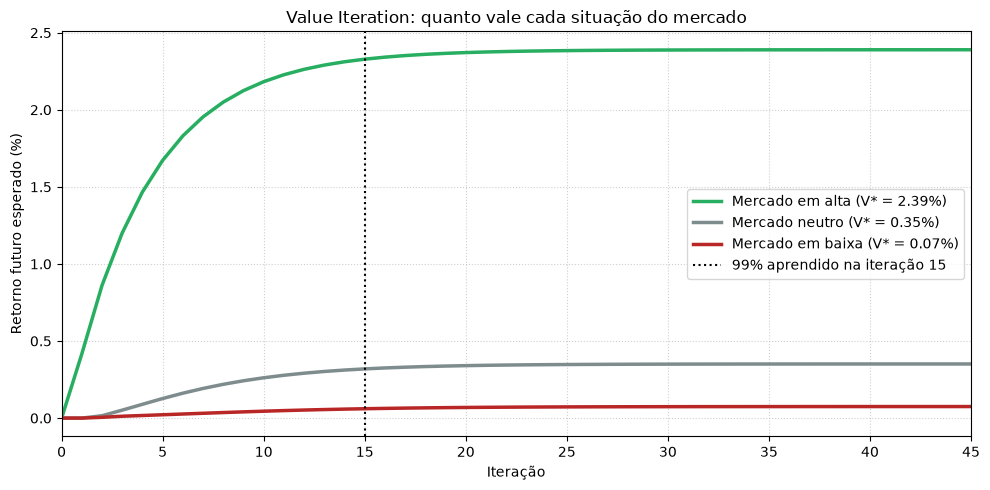

99% do valor ótimo na iteração 15; convergência total em 98 iterações


In [44]:
regimes = {"Mercado em alta": (2, "#27AE60"), "Mercado neutro": (1, "#7F8C8D"), "Mercado em baixa": (0, "#B92626")}
aprendido = 1 - np.abs(historico - V_star).max(axis=1) / np.abs(V_star).max()
k_bom = np.argmax(aprendido >= 0.99)   # iteração em que o robô já sabe 99% do valor ótimo

fig, ax = plt.subplots(figsize=(10, 5))
for nome, (b, cor) in regimes.items():
    s = idx(b, b, 0)   # regime estável, robô fora do mercado
    ax.plot(100 * historico[:, s], lw=2.5, color=cor, label=f"{nome} (V* = {100 * V_star[s]:.2f}%)")
ax.axvline(k_bom, color="black", ls=":", label=f"99% aprendido na iteração {k_bom}")
ax.set(title="Value Iteration: quanto vale cada situação do mercado",
       xlabel="Iteração", ylabel="Retorno futuro esperado (%)", xlim=(0, 3 * k_bom))
ax.grid(True, ls=":", alpha=0.6)
ax.legend()
plt.tight_layout()
plt.savefig("curva_value_iteration.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"99% do valor ótimo na iteração {k_bom}; convergência total em {len(historico) - 1} iterações")

## 7. Testes do modelo
Verificações automáticas de que os dados, o modelo e a solução estão consistentes (✅ = passou).

In [45]:
resultados_testes = []

def teste(nome, cond):
    print("✅" if cond else "❌", nome)
    resultados_testes.append(bool(cond))

teste("Sem NaN nas séries", not df[["rho", "x", "b", "feature_b_t", "feature_b_tm1"]].isna().any().any())
teste("Treino termina antes do teste", df_treino.index.max() < df_teste.index.min())
teste("feature_b_tm1 é o b defasado", (df["feature_b_tm1"].values[1:] == df["b"].values[:-1]).all())
teste("27 estados com índices únicos 0..26", sorted(idx(*s) for s in ESTADOS) == list(range(nS)))
teste("Cada linha de P̂(·|s,a) soma 1", np.allclose(P_hat.sum(axis=2), 1))
teste("Transição determinística: φ_t vira o lag e h_t = a_t",
      all(P_hat[idx(*s), ia, idx(*s2)] == 0
          for s in ESTADOS for ia, a in enumerate(ACOES) for s2 in ESTADOS
          if s2[1] != s[0] or s2[2] != a))
teste("Neutro mantido (a = h = 0) tem recompensa zero", np.allclose(R_hat[idx(1, 1, 0), 1], 0))

Q_check = np.einsum("sat,sat->sa", P_hat, R_hat + GAMMA * V_star)
teste("V* é ponto fixo de Bellman (resíduo < 1e-8)", np.abs(Q_check.max(axis=1) - V_star).max() < 1e-8)
teste("π* é gulosa em relação a Q*", (Q_check.argmax(axis=1) == pi_star).all())

print(f"\n{sum(resultados_testes)}/{len(resultados_testes)} testes passaram")
assert all(resultados_testes), "Algum teste falhou"

✅ Sem NaN nas séries
✅ Treino termina antes do teste
✅ feature_b_tm1 é o b defasado
✅ 27 estados com índices únicos 0..26
✅ Cada linha de P̂(·|s,a) soma 1
✅ Transição determinística: φ_t vira o lag e h_t = a_t
✅ Neutro mantido (a = h = 0) tem recompensa zero
✅ V* é ponto fixo de Bellman (resíduo < 1e-8)
✅ π* é gulosa em relação a Q*

9/9 testes passaram


---
# Parte III. Monte Carlo (model-free)
O Monte Carlo **não usa** $\widehat P$ nem $\widehat R$. Ele aprende só com experiência:

1. **Gera um episódio:** sorteia um dia do treino e uma posição inicial, e o agente opera dia após dia recebendo o retorno **real** daquele período. Como o agente não move o preço, reproduzir o histórico funciona como simulador.
2. **Calcula o retorno** de cada passo, de trás para frente: $G_t = R_{t+1} + \gamma\, G_{t+1}$
3. **Atualiza** $Q(s,a)$ com a média dos retornos observados:
$$N(s,a) \leftarrow N(s,a) + 1, \qquad Q(s,a) \leftarrow Q(s,a) + \frac{1}{N(s,a)}\big[G_t - Q(s,a)\big]$$
4. **Melhora a política:** em cada estado, escolhe a ação de maior $Q$.

**Exploração ($\varepsilon$-greedy):** para conhecer todas as ações, o agente às vezes age ao acaso. A 1ª ação de cada episódio é sempre aleatória (*exploring starts*), e nas demais a chance $\varepsilon$ de agir ao acaso cai de 1 para 0,05 ao longo do treino.

**Duração do episódio:** o mercado não tem "fim de jogo", então cortamos o episódio. Ele tem $2H$ dias, com $\gamma^H < 10^{-4}$, e só os primeiros $H$ dias são usados para aprender. Assim todo retorno usado enxerga pelo menos $H$ dias à frente, e o corte praticamente não afeta o resultado.

### First-visit × every-visit
Num episódio, o agente pode passar várias vezes pelo mesmo par (estado, ação). A diferença entre as versões é **quais dessas passagens entram na média**:

| | First-visit | Every-visit |
|---|---|---|
| O que conta | só a **primeira** passagem por $(s,a)$ no episódio | **todas** as passagens |
| Vantagem | retornos mais independentes entre si | mais dados por episódio |
| Desvantagem | descarta muitas passagens | retornos do mesmo episódio são correlacionados |

As duas versões usam exatamente os mesmos dados de treino, κ, γ, H, ε, número de episódios e semente. Só muda a regra acima.

### Configuração comum

In [46]:
N_EPISODIOS = 30_000
EPS_INICIAL, EPS_FINAL = 1.0, 0.05
H = int(np.ceil(np.log(1e-4) / np.log(GAMMA)))   # γ^H < 1e-4

def politica_gulosa(Q, N):
    """Melhor ação em cada estado, ignorando ações nunca testadas. Estado nunca visitado → fora do mercado."""
    Qv = np.where(N > 0, Q, -np.inf)
    pi = Qv.argmax(axis=1)
    pi[N.sum(axis=1) == 0] = ACOES.index(0)
    return pi

print(f"{N_EPISODIOS:,} episódios por versão | episódio de {2 * H} dias, aprendendo nos primeiros H = {H}")

30,000 episódios por versão | episódio de 84 dias, aprendendo nos primeiros H = 42


## 8. Treinando o Monte Carlo
A mesma função treina as duas versões; o parâmetro `primeira_visita` escolhe a regra (`True` = first-visit, `False` = every-visit).

In [47]:
def monte_carlo(d, gamma, kappa, n_episodios, H, primeira_visita, seed=SEED, a_cada=250):
    rng = np.random.default_rng(seed)
    b = d["b"].values.astype(int)
    b_lag = d["feature_b_tm1"].values.astype(int)
    r = d["close"].pct_change().shift(-1).values   # r_{t+1}
    Q, N = np.zeros((nS, nA)), np.zeros((nS, nA))
    hist = []

    for k in range(n_episodios):
        eps = max(EPS_FINAL, EPS_INICIAL - (EPS_INICIAL - EPS_FINAL) * k / (0.6 * n_episodios))
        t0 = rng.integers(1, len(d) - 2 * H - 1)    # dia inicial sorteado
        h = int(rng.choice(ACOES))                  # posição inicial sorteada

        # 1) gera o episódio
        S, A, R = [], [], []
        for t in range(t0, t0 + 2 * H):
            s = idx(b[t], b_lag[t], h)
            if t == t0 or rng.random() < eps:       # exploring start + ε-greedy
                ia = int(rng.integers(nA))
            else:
                ia = int(Q[s].argmax())
            a = ACOES[ia]
            R.append(np.log(max(1 + a * r[t] - kappa * abs(a - h), 1e-12)))
            S.append(s); A.append(ia)
            h = a

        # 2) e 3) retornos de trás para frente e atualização da média
        primeira = {}
        for i, sa in enumerate(zip(S, A)):
            primeira.setdefault(sa, i)
        G = 0.0
        for i in reversed(range(2 * H)):
            G = R[i] + gamma * G
            sa = (S[i], A[i])
            conta = (primeira[sa] == i) if primeira_visita else True
            if i < H and conta:
                N[sa] += 1
                Q[sa] += (G - Q[sa]) / N[sa]

        if (k + 1) % a_cada == 0:
            vis = N > 0
            hist.append({"episodio": k + 1,
                         "acordo_pi_VI": (politica_gulosa(Q, N) == pi_star).mean(),
                         "erro_Q": np.abs(Q - Q_star)[vis].mean()})
    return Q, N, pd.DataFrame(hist)

mc = {}
for nome, pv in [("first-visit", True), ("every-visit", False)]:
    Q, N, hst = monte_carlo(df_treino, GAMMA, KAPPA, N_EPISODIOS, H, primeira_visita=pv)
    mc[nome] = {"Q": Q, "N": N, "hist": hst, "pi": politica_gulosa(Q, N)}
    print(f"{nome:12s} | atualizações: {int(N.sum()):>9,} | pares (s,a) visitados: {(N > 0).sum()}/{nS * nA}")

first-visit  | atualizações:   388,071 | pares (s,a) visitados: 72/81
every-visit  | atualizações: 1,260,000 | pares (s,a) visitados: 72/81


## 9. Escolha da versão principal
**Critério (definido antes de olhar qualquer resultado):** fica como principal a versão com **maior Sharpe no período de treino**, com a política aprendida operando os mesmos dados em que foi treinada. O teste não participa da escolha, para não enviesar a avaliação final.

Também mostramos, como informação complementar:
- **Concordância com o VI:** em quantos dos 27 estados o MC escolhe a mesma ação que o Value Iteration.
- **Erro de $Q$:** distância média entre o $Q$ do MC e o $Q^*$ do Value Iteration.

Concordar com o VI não é a meta em si: o VI é ótimo para o *modelo estimado* de 27 estados, não para o mercado real.

In [48]:
def sharpe_treino(pi):
    """Sharpe da política operando o treino (mesma fórmula de recompensa e corretagem do MDP)."""
    h, lr = 0, []
    r = df_treino["close"].pct_change().shift(-1).values
    for t, (b0, b1) in enumerate(zip(df_treino["b"], df_treino["feature_b_tm1"].astype(int))):
        a = ACOES[pi[idx(b0, b1, h)]]
        if not np.isnan(r[t]):
            lr.append(np.log(max(1 + a * r[t] - KAPPA * abs(a - h), 1e-12)))
        h = a
    ex = np.array(lr) - df_treino["rf"].values[:len(lr)]
    return ex.mean() / ex.std() * np.sqrt(PERIODOS_ANO)

escolha = pd.DataFrame({
    nome: {"Sharpe no treino": sharpe_treino(v["pi"]),
           "Concordância com VI": f"{(v['pi'] == pi_star).sum()}/{nS}",
           "Erro médio |Q − Q*|": np.abs(v["Q"] - Q_star)[v["N"] > 0].mean()}
    for nome, v in mc.items()}).T
display(escolha.style.format({"Sharpe no treino": "{:.2f}", "Erro médio |Q − Q*|": "{:.5f}"}))

VERSAO_MC = escolha["Sharpe no treino"].astype(float).idxmax()
NOME_MC = f"Monte Carlo ({VERSAO_MC})"
Q_mc, N_mc, pi_mc = mc[VERSAO_MC]["Q"], mc[VERSAO_MC]["N"], mc[VERSAO_MC]["pi"]
print(f"Versão principal: {NOME_MC}. É ela que segue para o simulador e o benchmark.")

comparacao = pd.DataFrame(ESTADOS, columns=["φ(x_t)", "φ(x_t-1)", "h_t-1"])
comparacao["a* VI"] = np.array(ACOES)[pi_star]
for nome, v in mc.items():
    comparacao[f"a* {nome}"] = np.array(ACOES)[v["pi"]]
comparacao[["Q_MC(-1)", "Q_MC(0)", "Q_MC(+1)"]] = Q_mc
comparacao["visitas (-1 / 0 / +1)"] = [" / ".join(str(int(n)) for n in linha) for linha in N_mc]
comparacao["MC = VI"] = np.where(pi_mc == pi_star, "✓", "✗")
print(f"\nTabela por estado (Q e visitas da versão principal, {VERSAO_MC}):")
display(comparacao.round(5))

teste("Q do MC finito nos pares visitados", all(np.isfinite(v["Q"][v["N"] > 0]).all() for v in mc.values()))
teste("Políticas MC só usam ações válidas", all(set(np.array(ACOES)[v["pi"]]) <= set(ACOES) for v in mc.values()))
teste("Every-visit faz pelo menos tantas atualizações quanto first-visit",
      mc["every-visit"]["N"].sum() >= mc["first-visit"]["N"].sum())

,Sharpe no treino,Concordância com VI,Erro médio |Q − Q*|
first-visit,1.12,20/27,0.00758
every-visit,1.20,22/27,0.00726


Versão principal: Monte Carlo (every-visit). É ela que segue para o simulador e o benchmark.

Tabela por estado (Q e visitas da versão principal, every-visit):


,φ(x_t),φ(x_t-1),h_t-1,a* VI,a* first-visit,a* every-visit,Q_MC(-1),Q_MC(0),Q_MC(+1),visitas (-1 / 0 / +1),MC = VI
0,0,0,-1,0,0,0,-0.00535,-0.00293,-0.00647,12678 / 35907 / 11153,✓
1,0,0,0,0,1,0,-0.00642,0.00005,-0.00338,20643 / 185330 / 20445,✓
2,0,0,1,1,1,1,-0.00893,-0.00462,0.00029,13440 / 15897 / 69820,✓
3,0,1,-1,-1,-1,-1,0.00716,-0.00464,-0.01399,3201 / 894 / 898,✓
4,0,1,0,-1,0,-1,0.00299,-0.00316,-0.01067,11656 / 1393 / 1378,✓
5,0,1,1,-1,-1,0,-0.00586,-0.00006,-0.00540,1051 / 6464 / 1042,✗
6,0,2,-1,-1,0,0,0.00000,0.00000,0.00000,0 / 0 / 0,✗
7,0,2,0,0,0,0,0.00000,0.00000,0.00000,0 / 0 / 0,✓
8,0,2,1,1,0,0,0.00000,0.00000,0.00000,0 / 0 / 0,✗
9,1,0,-1,-1,-1,0,-0.00318,-0.00249,-0.00450,2988 / 986 / 845,✗


✅ Q do MC finito nos pares visitados
✅ Políticas MC só usam ações válidas
✅ Every-visit faz pelo menos tantas atualizações quanto first-visit


## 10. Curvas de aprendizado do Monte Carlo
À esquerda, a concordância com o Value Iteration ao longo dos episódios; à direita, o erro médio $|Q_{MC} - Q^*|$.

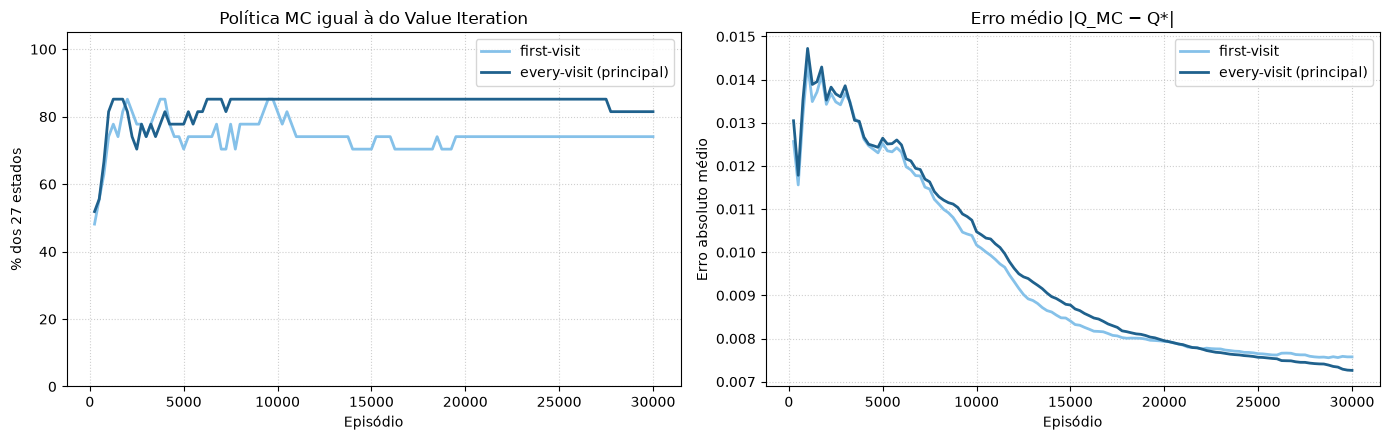

In [49]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for nome, cor in [("first-visit", "#85C1E9"), ("every-visit", "#1F618D")]:
    hst = mc[nome]["hist"]
    rotulo = nome + (" (principal)" if nome == VERSAO_MC else "")
    ax1.plot(hst["episodio"], 100 * hst["acordo_pi_VI"], color=cor, lw=2, label=rotulo)
    ax2.plot(hst["episodio"], hst["erro_Q"], color=cor, lw=2, label=rotulo)
ax1.set(title="Política MC igual à do Value Iteration", xlabel="Episódio", ylabel="% dos 27 estados", ylim=(0, 105))
ax2.set(title="Erro médio |Q_MC − Q*|", xlabel="Episódio", ylabel="Erro absoluto médio")
for ax in (ax1, ax2):
    ax.grid(True, ls=":", alpha=0.6)
    ax.legend()
plt.tight_layout()
plt.savefig("curva_monte_carlo.png", dpi=300, bbox_inches="tight")
plt.show()

---
# Parte IV. Avaliação
## 11. Políticas no simulador `gym-trading-env`
Cada política opera no simulador, começando com US$ 1.000, no treino e no teste.

| Estratégia | O que faz |
|---|---|
| MDP (Value Iteration) | política ótima do modelo estimado, executada de forma gulosa (sempre a melhor ação) |
| Monte Carlo | política aprendida sem modelo (versão escolhida na seção 9), executada de forma gulosa |
| Buy & Hold | compra no 1º dia e segura |
| Fora do mercado | nunca opera (referência de risco zero) |
| Aleatória | ação sorteada todo dia (referência de "sem inteligência") |

**Métricas:** retorno total e anual; **Sharpe** (retorno acima da taxa livre de risco dividido pela volatilidade, quanto maior melhor); **max drawdown** (maior queda do pico ao fundo); **Calmar** (retorno anual dividido pelo max drawdown: quanto se ganha por unidade de perda máxima, quanto maior melhor); **nº de trocas** (quanto mais trocas, mais corretagem).

In [50]:
def criar_env(d):
    return TradingEnv(df=d, name=TICKER, positions=ACOES, initial_position=0,
                      trading_fees=KAPPA, borrow_interest_rate=0,
                      portfolio_initial_value=1000, verbose=0)

def rodar_no_ambiente(d, politica, epsilon=0.0, seed=SEED):
    rng = np.random.default_rng(seed)
    env = criar_env(d)
    obs, info = env.reset(seed=seed)
    h = 0
    valores, recompensas, acoes = [info["portfolio_valuation"]], [], []
    for _ in range(len(d) - 1):
        a = politica(int(obs[0]), int(obs[1]), h)
        if rng.random() < epsilon:   # ε-greedy
            a = int(rng.choice(ACOES))
        obs, r, done, truncated, info = env.step(ACOES.index(a))
        valores.append(info["portfolio_valuation"])
        recompensas.append(r)
        acoes.append(a)
        h = a
        if done or truncated:
            break
    env.close()
    return pd.Series(valores, index=d.index[:len(valores)]), np.array(recompensas), np.array(acoes)

def metricas(valores, acoes):
    lr = np.log(valores).diff().dropna()
    ex = lr - df["rf"].loc[lr.index]   # retorno em excesso à taxa livre
    tot = valores.iloc[-1] / valores.iloc[0]
    anual = tot ** (PERIODOS_ANO / len(lr)) - 1
    mdd = (valores / valores.cummax() - 1).min()
    return {
        "Patrimônio final": valores.iloc[-1],
        "Retorno total": tot - 1,
        "Retorno anual": anual,
        "Sharpe": ex.mean() / ex.std() * np.sqrt(PERIODOS_ANO) if lr.std() > 0 else 0.0,
        "Max drawdown": mdd,
        "Calmar": anual / abs(mdd) if mdd < 0 else np.nan,   # retorno anual / perda máxima
        "Nº de trocas": int((np.diff(acoes, prepend=0) != 0).sum()),
    }

politicas = {   # nome: (política, ε)
    "MDP (Value Iteration)": (lambda b0, b1, h: ACOES[pi_star[idx(b0, b1, h)]], 0.0),
    NOME_MC:                 (lambda b0, b1, h: ACOES[pi_mc[idx(b0, b1, h)]], 0.0),
    "Buy & Hold":            (lambda b0, b1, h: 1, 0.0),
    "Fora do mercado":       (lambda b0, b1, h: 0, 0.0),
    "Aleatória":             (lambda b0, b1, h: 0, 1.0),
}

resultados, curvas = {}, {}
for conjunto, dados in [("Treino", df_treino), ("Teste", df_teste)]:
    for nome, (pol, eps) in politicas.items():
        v, r, a = rodar_no_ambiente(dados, pol, epsilon=eps)
        resultados[(conjunto, nome)] = metricas(v, a)
        curvas[(conjunto, nome)] = (v, r, a)

display(pd.DataFrame(resultados).T.style.format({
    "Patrimônio final": "US$ {:,.2f}", "Retorno total": "{:.2%}", "Retorno anual": "{:.2%}", "Sharpe": "{:.2f}",
    "Max drawdown": "{:.2%}", "Calmar": "{:.2f}", "Nº de trocas": "{:.0f}",
}, na_rep="—"))

### Política gulosa × ε-greedy
Na execução **gulosa**, o agente sempre escolhe a ação de maior valor. No **ε-greedy**, com probabilidade $\varepsilon = 0{,}1$ ele sorteia uma ação ao acaso, ou seja, $\pi(a^* \mid s) = 1 - \varepsilon + \varepsilon/3$.

Como o resultado do ε-greedy depende do sorteio, ele é rodado com 100 sementes e mostramos a **média**. A última coluna diz em quantas sementes o ε-greedy superou o Sharpe da política gulosa.

In [51]:
EPS_EXEC = 0.1      # ε-greedy na execução: com probabilidade ε a ação é sorteada
N_SEMENTES = 100    # o ε-greedy é aleatório, então rodamos várias vezes e tiramos a média

comparacao_eps = {}
for conjunto, dados in [("Treino", df_treino), ("Teste", df_teste)]:
    for nome, pi in [("MDP (Value Iteration)", pi_star), (NOME_MC, pi_mc)]:
        politica = lambda b0, b1, h, pi=pi: ACOES[pi[idx(b0, b1, h)]]
        gulosa = resultados[(conjunto, nome)]
        sorteios = pd.DataFrame([metricas(v, a) for v, _, a in
                                 (rodar_no_ambiente(dados, politica, epsilon=EPS_EXEC, seed=s) for s in range(N_SEMENTES))])
        comparacao_eps[(conjunto, nome, "gulosa")] = {**gulosa, "ε-greedy > gulosa": np.nan}
        comparacao_eps[(conjunto, nome, f"ε-greedy (média de {N_SEMENTES})")] = {
            **sorteios.mean(), "ε-greedy > gulosa": (sorteios["Sharpe"] > gulosa["Sharpe"]).mean()}

colunas = ["Retorno anual", "Sharpe", "Max drawdown", "Calmar", "Nº de trocas", "ε-greedy > gulosa"]
display(pd.DataFrame(comparacao_eps).T[colunas].style.format({
    "Retorno anual": "{:.2%}", "Sharpe": "{:.2f}", "Max drawdown": "{:.2%}", "Calmar": "{:.2f}",
    "Nº de trocas": "{:.0f}", "ε-greedy > gulosa": "{:.0%}"}, na_rep="—"))

### Monte Carlo com 5 sementes
O Monte Carlo é aleatório: a **semente** define os dias sorteados, as posições iniciais e as ações exploratórias. Com uma única rodada de 30.000 episódios, não dá para saber se o resultado foi sorte.

Por isso treinamos cada versão com **5 sementes** (a semente 42, usada até aqui, é uma delas). Todo o resto é igual. Para cada métrica mostramos a **média**, o **desvio padrão** e a **variância** entre as sementes. As métricas de teste usam a política gulosa no simulador.

Resultado de cada semente:



Média, desvio padrão e variância entre as 5 sementes:


first-visit  | mesma ação nas 5 sementes em 17/27 estados
every-visit  | mesma ação nas 5 sementes em 19/27 estados
Pela média do Sharpe no treino, a melhor versão é first-visit (com uma semente, a seção 9 escolheu every-visit).


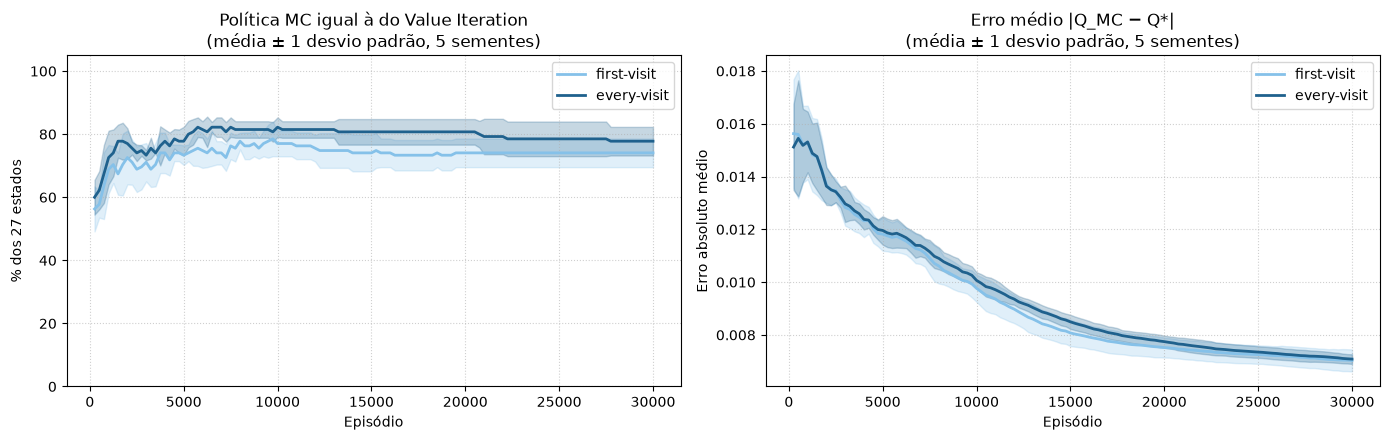

In [52]:
SEMENTES_MC = [SEED + k for k in range(5)]   # 42, 43, 44, 45, 46

sem_linhas, sem_pi, sem_hist = [], {}, {}
for nome, pv in [("first-visit", True), ("every-visit", False)]:
    for s in SEMENTES_MC:
        if s == SEED:   # já treinado na seção 8
            Qs, Ns, hs = mc[nome]["Q"], mc[nome]["N"], mc[nome]["hist"]
        else:
            Qs, Ns, hs = monte_carlo(df_treino, GAMMA, KAPPA, N_EPISODIOS, H, primeira_visita=pv, seed=s)
        pis = politica_gulosa(Qs, Ns)
        vs, _, acs = rodar_no_ambiente(df_teste, lambda b0, b1, h, pis=pis: ACOES[pis[idx(b0, b1, h)]])
        m = metricas(vs, acs)
        sem_pi[(nome, s)], sem_hist[(nome, s)] = pis, hs
        sem_linhas.append({"Versão": nome, "Semente": s,
                           "Sharpe treino": sharpe_treino(pis),
                           "Concordância VI": (pis == pi_star).sum(),
                           "Erro |Q − Q*|": np.abs(Qs - Q_star)[Ns > 0].mean(),
                           "Retorno anual teste": m["Retorno anual"],
                           "Sharpe teste": m["Sharpe"],
                           "Max drawdown teste": m["Max drawdown"],
                           "Calmar teste": m["Calmar"],
                           "Nº de trocas teste": m["Nº de trocas"]})

sem = pd.DataFrame(sem_linhas).set_index(["Versão", "Semente"])
fmt_sem = {"Sharpe treino": "{:.2f}", "Concordância VI": "{:.1f}", "Erro |Q − Q*|": "{:.5f}",
           "Retorno anual teste": "{:.2%}", "Sharpe teste": "{:.2f}", "Max drawdown teste": "{:.2%}",
           "Calmar teste": "{:.2f}", "Nº de trocas teste": "{:.1f}"}
print("Resultado de cada semente:")
display(sem.style.format({**fmt_sem, "Concordância VI": "{:.0f}/27", "Nº de trocas teste": "{:.0f}"}))

# média, desvio padrão (amostral) e variância entre as 5 sementes
resumo_sem = pd.concat(
    {v: sem.loc[v].agg(["mean", "std", "var"]).set_axis(["Média", "Desvio padrão", "Variância"])
     for v in ["first-visit", "every-visit"]}, names=["Versão", "Estatística"])
linhas_var = pd.IndexSlice[resumo_sem.index.get_level_values("Estatística") == "Variância", :]
print(f"\nMédia, desvio padrão e variância entre as {len(SEMENTES_MC)} sementes:")
display(resumo_sem.style.format(fmt_sem).format("{:.4g}", subset=linhas_var))

for nome in ["first-visit", "every-visit"]:
    P = np.array([sem_pi[(nome, s)] for s in SEMENTES_MC])
    print(f"{nome:12s} | mesma ação nas {len(SEMENTES_MC)} sementes em {(P == P[0]).all(axis=0).sum()}/{nS} estados")
melhor = resumo_sem.xs("Média", level="Estatística")["Sharpe treino"].astype(float).idxmax()
print(f"Pela média do Sharpe no treino, a melhor versão é {melhor} (com uma semente, a seção 9 escolheu {VERSAO_MC}).")

# curvas de aprendizado: média ± 1 desvio padrão entre as sementes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for nome, cor in [("first-visit", "#85C1E9"), ("every-visit", "#1F618D")]:
    ep = sem_hist[(nome, SEED)]["episodio"]
    for ax, col, escala in [(ax1, "acordo_pi_VI", 100), (ax2, "erro_Q", 1)]:
        y = escala * np.array([sem_hist[(nome, s)][col] for s in SEMENTES_MC])
        media, dp = y.mean(axis=0), y.std(axis=0, ddof=1)
        ax.plot(ep, media, color=cor, lw=2, label=nome)
        ax.fill_between(ep, media - dp, media + dp, color=cor, alpha=0.25)
ax1.set(title=f"Política MC igual à do Value Iteration\n(média ± 1 desvio padrão, {len(SEMENTES_MC)} sementes)",
        xlabel="Episódio", ylabel="% dos 27 estados", ylim=(0, 105))
ax2.set(title=f"Erro médio |Q_MC − Q*|\n(média ± 1 desvio padrão, {len(SEMENTES_MC)} sementes)", xlabel="Episódio", ylabel="Erro absoluto médio")
for ax in (ax1, ax2):
    ax.grid(True, ls=":", alpha=0.6)
    ax.legend()
plt.tight_layout()
plt.savefig("curva_monte_carlo_sementes.png", dpi=300, bbox_inches="tight")
plt.show()

## 12. Testes do ambiente
Confere se o simulador se comporta como o modelo supõe. A única diferença conhecida é no *short* mantido: o simulador não rebalanceia a posição vendida para −100% todo dia, então a recompensa difere levemente nesses passos.

In [53]:
c = df_teste["close"].values
v_mdp, r_env, a_mdp = curvas[("Teste", "MDP (Value Iteration)")]
v_fora = curvas[("Teste", "Fora do mercado")][0]
v_bh = curvas[("Teste", "Buy & Hold")][0]

obs, _ = criar_env(df_teste).reset(seed=SEED)
teste("Observação inicial = [φ(x_t), φ(x_t-1)] da 1ª linha do teste",
      obs[0] == df_teste["feature_b_t"].iloc[0] and obs[1] == df_teste["feature_b_tm1"].iloc[0])
teste(f"Episódio cobre o teste inteiro ({len(a_mdp)} de {len(df_teste) - 1} passos)",
      len(a_mdp) >= len(df_teste) - 2)
teste("Fora do mercado mantém o patrimônio em 1000", np.allclose(v_fora, 1000))

erro_bh = abs(v_bh.iloc[-1] / (1000 * (1 - KAPPA) * c[len(v_bh) - 1] / c[0]) - 1)
teste(f"Buy & Hold acompanha o preço (erro {erro_bh:.3%})", erro_bh < 0.01)

n = len(a_mdp)
h_prev = np.concatenate([[0], a_mdp[:-1]])
R_formula = np.log(1 + a_mdp * (c[1:n + 1] / c[:n] - 1) - KAPPA * np.abs(a_mdp - h_prev))
diff = np.abs(r_env - R_formula)
short_mantido = (a_mdp == -1) & (h_prev == -1)
print(f"|R_env - R_fórmula| médio: {diff[~short_mantido].mean():.2e} "
      f"| em short mantido: {diff[short_mantido].mean():.2e} ({short_mantido.sum()} passos)")
# No short o ambiente mantém fixa a quantidade vendida (não rebalanceia para -100%),
# por isso pequenas diferenças nesses passos são esperadas.
teste("Recompensa do ambiente = ln(1 + a·r - κ|a - h|) fora de short mantido",
      diff[~short_mantido].mean() < 1e-4)

✅ Observação inicial = [φ(x_t), φ(x_t-1)] da 1ª linha do teste
✅ Episódio cobre o teste inteiro (1777 de 1777 passos)
✅ Fora do mercado mantém o patrimônio em 1000
✅ Buy & Hold acompanha o preço (erro 0.000%)
|R_env - R_fórmula| médio: 1.42e-06 | em short mantido: 4.23e-04 (15 passos)
✅ Recompensa do ambiente = ln(1 + a·r - κ|a - h|) fora de short mantido


## 13. Gráficos do período de teste
Preço do ativo, patrimônio de cada estratégia e posição escolhida pelo Value Iteration.

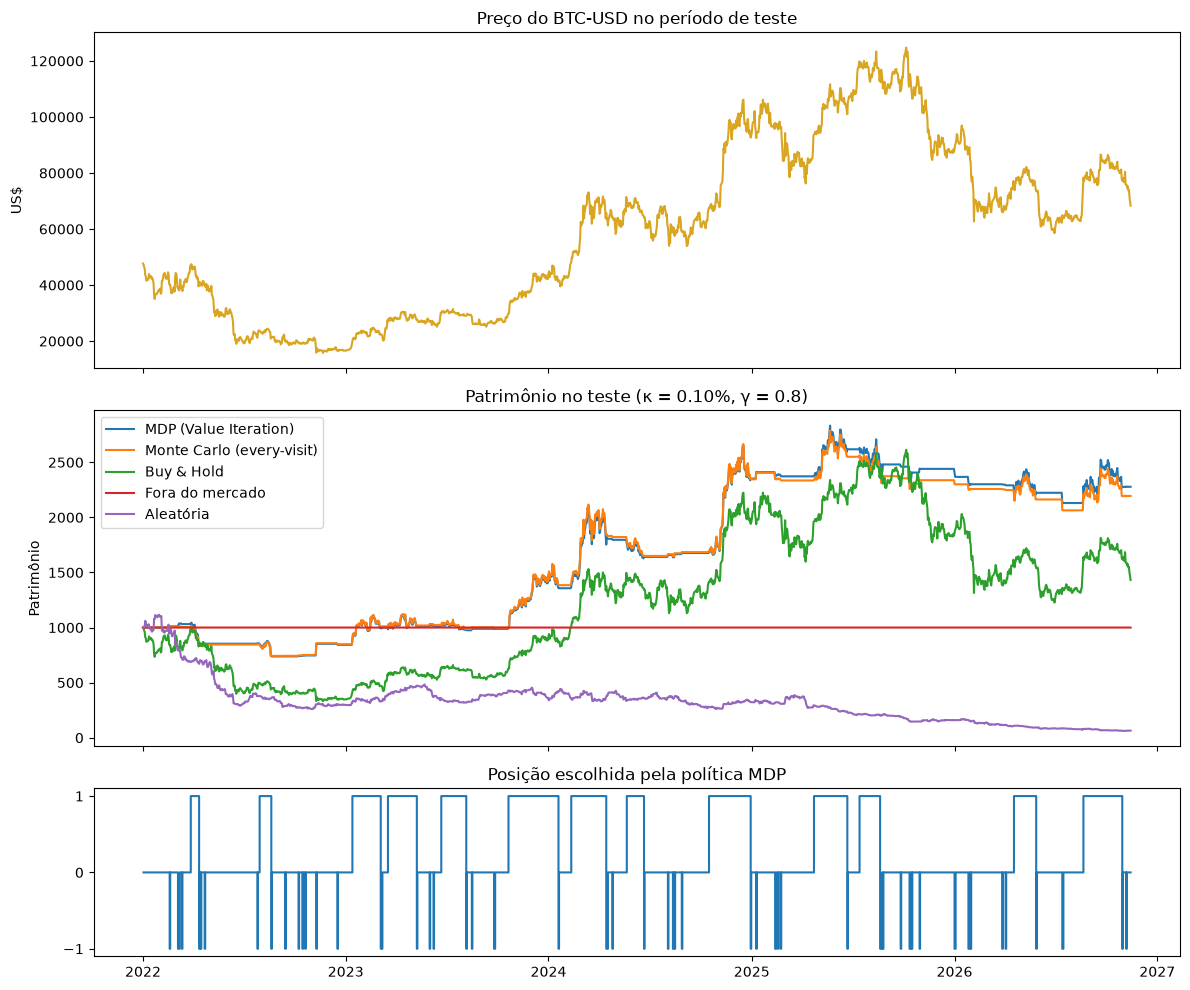

In [54]:
fig, ax = plt.subplots(3, 1, figsize=(12, 10), sharex=True, gridspec_kw={"height_ratios": [2, 2, 1]})

ax[0].plot(df_teste.index, df_teste["close"], color="goldenrod")
ax[0].set(title=f"Preço do {TICKER} no período de teste", ylabel="US$")

for nome in politicas:
    v = curvas[("Teste", nome)][0]
    ax[1].plot(v.index, v.values, label=nome)
ax[1].set(title=f"Patrimônio no teste (κ = {KAPPA:.2%}, γ = {GAMMA})", ylabel="Patrimônio")
ax[1].legend()

ax[2].step(v_mdp.index[1:len(a_mdp) + 1], a_mdp, where="post")
ax[2].set(title="Posição escolhida pela política MDP", yticks=[-1, 0, 1])

plt.tight_layout()
plt.savefig("grafico_teste.png", dpi=300, bbox_inches="tight")
plt.show()

## 14. Benchmark: RL × modelos econométricos
Comparamos as políticas de RL com os modelos clássicos da econometria para previsão de retornos. Todos são estimados **só no treino** (até 31/12/2021) e avaliados no **mesmo período de teste** do simulador (a partir de 01/01/2022).

Cada modelo prevê o log-retorno de amanhã (ou a probabilidade de alta), e a previsão vira posição: previsão positiva (ou $P(\text{alta}) > 50\%$) → comprado; caso contrário → vendido.

| Modelo | Equação |
|---|---|
| Passeio aleatório (Buy & Hold) | $r_{t+1} = \mu + \varepsilon_{t+1}$: retorno imprevisível; com $\mu > 0$, fica sempre comprado |
| AR(1) | $r_{t+1} = \alpha + \phi\, r_t + \varepsilon_{t+1}$, estimado por OLS |
| ARMA(1,1) | $r_{t+1} = \alpha + \phi\, r_t + \theta\, \varepsilon_t + \varepsilon_{t+1}$, por máxima verossimilhança |
| Regressão preditiva (OLS) | $r_{t+1} = \alpha + \beta' z_t + \varepsilon_{t+1}$, com $z_t = (x_t,\ \sigma_{20,t},\ r_t,\ r_{t-1})$ |
| Logit / Probit | $P(r_{t+1} > 0) = F(\alpha + \beta' z_t)$, com $F$ logística (Logit) ou normal (Probit) |
| Markov-switching (Hamilton, 1989) | 2 regimes, cada um com média e variância próprias; $E[r_{t+1}]$ vem das probabilidades filtradas (sem olhar o futuro) |

Todas as estratégias são simuladas com a mesma fórmula de retorno e corretagem. O ranking é ordenado pelo Sharpe e inclui o **Calmar** (retorno anual ÷ |max drawdown|).

In [55]:
def preparar_features(d):
    d = d.copy()
    d["rho_fwd"] = d["rho"].shift(-1)              # r_{t+1} (alvo)
    d["alvo"] = (d["rho_fwd"] > 0).astype(int)     # 1 = alta amanhã
    d["vol_20"] = d["rho"].rolling(20).std()
    d["rho_lag1"] = d["rho"]
    d["rho_lag2"] = d["rho"].shift(1)
    return d.dropna()

# features calculadas na série inteira (só usam o passado), para o teste começar em 01/01/2022 como no simulador;
# o treino para em 30/12/2021 porque o alvo de 31/12 já é o retorno do 1º dia de teste
feats = preparar_features(df)
tr = feats[feats.index < pd.Timestamp(CORTE) - pd.Timedelta(days=1)]
te = feats[feats.index >= CORTE]
FEATS = ["x", "vol_20", "rho_lag1", "rho_lag2"]
X_tr, X_te = sm.add_constant(tr[FEATS]), sm.add_constant(te[FEATS], has_constant="add")

def sinal(previsao):   # previsão > 0 → comprado (+1); caso contrário → vendido (−1)
    return np.where(np.asarray(previsao) > 0, 1, -1)

def posicoes_mdp(d, pi=None):
    pi = pi_star if pi is None else pi
    h, pos = 0, []
    for b0, b1 in zip(d["b"], d["feature_b_tm1"].astype(int)):
        h = ACOES[pi[idx(b0, b1, h)]]
        pos.append(h)
    return pos

pos = pd.DataFrame(index=te.index)
pos["MDP (Value Iteration)"] = posicoes_mdp(te)
pos[NOME_MC] = posicoes_mdp(te, pi_mc)
pos["Passeio aleatório (Buy & Hold)"] = 1   # E[r_{t+1}] = μ > 0 → sempre comprado

# AR(1) e regressão preditiva, por OLS
ar1 = sm.OLS(tr["rho_fwd"], sm.add_constant(tr[["rho_lag1"]])).fit()
pos["AR(1)"] = sinal(ar1.predict(sm.add_constant(te[["rho_lag1"]], has_constant="add")))
ols = sm.OLS(tr["rho_fwd"], X_tr).fit()
pos["Regressão preditiva (OLS)"] = sinal(ols.predict(X_te))

# Logit e Probit: P(alta amanhã) > 50% → comprado
for nome, familia in [("Logit", sm.Logit), ("Probit", sm.Probit)]:
    pos[nome] = sinal(familia(tr["alvo"], X_tr).fit(disp=0).predict(X_te) - 0.5)

# ARMA(1,1) e Markov-switching: estimados com os log-retornos (em %) do treino e aplicados à série inteira,
# o que gera a previsão de r_{t+1} usando só dados até t
r_pct = 100 * df["rho"]
n_tr = (r_pct.index < CORTE).sum()
arma = ARIMA(r_pct.values[:n_tr], order=(1, 0, 1)).fit()
prev_arma = pd.Series(arma.apply(r_pct.values).fittedvalues, index=r_pct.index).shift(-1)
pos["ARMA(1,1)"] = sinal(prev_arma.loc[te.index])

np.random.seed(SEED)
ms = MarkovRegression(r_pct.values[:n_tr], k_regimes=2, switching_variance=True).fit(search_reps=20)
filtradas = MarkovRegression(r_pct.values, k_regimes=2, switching_variance=True).filter(ms.params).filtered_marginal_probabilities
par = dict(zip(ms.model.param_names, ms.params))
mu = np.array([par["const[0]"], par["const[1]"]])   # retorno médio diário de cada regime (%)
prev_ms = pd.Series(filtradas @ ms.regime_transition[:, :, 0].T @ mu, index=r_pct.index)
pos["Markov-switching (Hamilton)"] = sinal(prev_ms.loc[te.index])

print(f"Regressão preditiva no treino: R² = {ols.rsquared:.4f} | menor p-valor dos coeficientes = {ols.pvalues.drop('const').min():.3f}")
print(f"Markov-switching: retorno médio diário por regime = {mu[0]:.3f}% e {mu[1]:.3f}%")

r_fwd = df["close"].pct_change().shift(-1).loc[te.index]   # r_{t+1}

def simular(p):
    p = pd.Series(np.asarray(p, dtype=float), index=te.index)
    h = p.shift(fill_value=0.0)
    lr = np.log(np.maximum(1 + p * r_fwd - KAPPA * (p - h).abs(), 1e-12))
    return 1000 * np.exp(lr.cumsum()), lr, int((p != h).sum())   # patrimônio partindo de US$ 1.000

linhas, df_curvas = {}, pd.DataFrame(index=te.index)
for nome in pos:
    curva, lr, trocas = simular(pos[nome])
    df_curvas[nome] = curva
    tot = curva.iloc[-1] / 1000 - 1
    anual = (1 + tot) ** (PERIODOS_ANO / len(lr)) - 1
    mdd = (curva / np.maximum(curva.cummax(), 1000) - 1).min()
    ex = lr - te["rf"]
    linhas[nome] = {
        "Patrimônio Final": curva.iloc[-1],
        "Retorno Total": tot,
        "Retorno Anual": anual,
        "Índice Sharpe": ex.mean() / ex.std() * np.sqrt(PERIODOS_ANO),
        "Max Drawdown": mdd,
        "Calmar": anual / abs(mdd),
        "Turnover (Trocas)": trocas,
    }

df_ranking = pd.DataFrame(linhas).T.sort_values("Índice Sharpe", ascending=False)
display(df_ranking.style.format({
    "Patrimônio Final": "US$ {:,.2f}", "Retorno Total": "{:+.2%}", "Retorno Anual": "{:+.2%}", "Índice Sharpe": "{:.2f}",
    "Max Drawdown": "{:.2%}", "Calmar": "{:.2f}", "Turnover (Trocas)": "{:.0f}",
}))

Regressão preditiva no treino: R² = 0.0020 | menor p-valor dos coeficientes = 0.074
Markov-switching: retorno médio diário por regime = 0.225% e 0.141%


,Patrimônio Final,Retorno Total,Retorno Anual,Índice Sharpe,Max Drawdown,Calmar,Turnover (Trocas)
MDP (Value Iteration),"US$ 2,268.57",+126.86%,+18.32%,0.46,-29.35%,0.62,113
Monte Carlo (every-visit),"US$ 2,194.64",+119.46%,+17.52%,0.44,-26.95%,0.65,108
AR(1),"US$ 2,287.75",+128.77%,+18.53%,0.26,-73.07%,0.25,49
"ARMA(1,1)","US$ 2,172.32",+117.23%,+17.27%,0.24,-72.85%,0.24,43
Probit,"US$ 1,676.72",+67.67%,+11.20%,0.13,-72.95%,0.15,113
Logit,"US$ 1,633.51",+63.35%,+10.61%,0.12,-72.95%,0.15,115
Passeio aleatório (Buy & Hold),"US$ 1,431.89",+43.19%,+7.65%,0.07,-66.93%,0.11,1
Markov-switching (Hamilton),"US$ 1,431.89",+43.19%,+7.65%,0.07,-66.93%,0.11,1
Regressão preditiva (OLS),US$ 521.59,-47.84%,-12.51%,-0.34,-77.59%,-0.16,224


## 15. Risco × retorno, Sharpe e Calmar
À esquerda, cada ponto é um modelo: quanto mais **para cima e para a esquerda**, melhor (mais retorno com menos queda). No centro, o Sharpe; à direita, o Calmar (retorno anual por unidade de perda máxima).

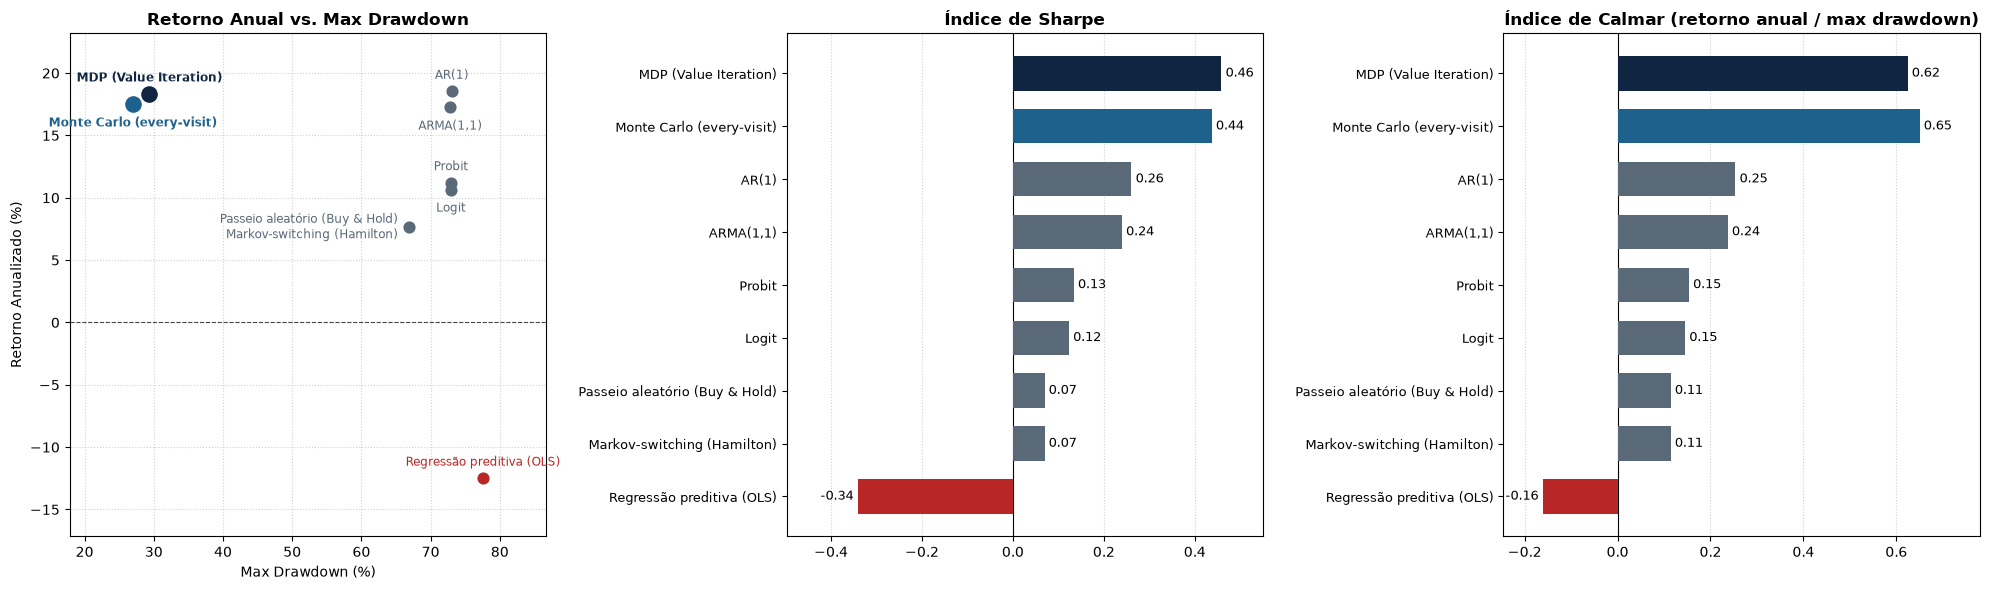

In [56]:
nomes = df_ranking.index
ret_anual = df_ranking["Retorno Anual"] * 100
drawdowns = -df_ranking["Max Drawdown"] * 100
cores = {n: "#102542" if "MDP" in n else "#1F618D" if "Monte Carlo" in n else "#5A6978" if s > 0 else "#B92626"
         for n, s in df_ranking["Índice Sharpe"].items()}

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(20, 6))

# modelos com resultado idêntico (ex.: Markov-switching = Buy & Hold) viram um único ponto com os dois nomes
pontos = df_ranking.groupby([drawdowns.round(2), ret_anual.round(2)], sort=False).groups
rotulados = []
for (x, y), grupo in pontos.items():
    nome, cor = "\n".join(grupo), cores[grupo[0]]
    rl = "MDP" in nome or "Monte Carlo" in nome
    ax1.scatter(x, y, color=cor, s=120 if rl else 60, zorder=3)
    if len(grupo) > 1:                                                              # vários modelos no ponto → rótulo à esquerda
        xytext, ha, va = (-8, 0), "right", "center"
    elif any(abs(x - x0) < 6 and abs(y - y0) < 2.5 for x0, y0 in rotulados):        # vizinho já rotulado → rótulo embaixo
        xytext, ha, va = (0, -9), "center", "top"
    else:
        xytext, ha, va = (0, 7), "center", "bottom"
    ax1.annotate(nome, (x, y), xytext=xytext, textcoords="offset points", ha=ha, va=va,
                 fontsize=8.5, color=cor, weight="bold" if rl else "normal")
    rotulados.append((x, y))
ax1.axhline(0, color="black", ls="--", lw=0.8, alpha=0.7)
ax1.margins(x=0.18, y=0.15)
ax1.set_title("Retorno Anual vs. Max Drawdown", fontsize=12, fontweight="bold")
ax1.set(xlabel="Max Drawdown (%)", ylabel="Retorno Anualizado (%)")
ax1.grid(True, ls=":", alpha=0.6)

y = np.arange(len(nomes))
for ax, coluna, titulo in [(ax2, "Índice Sharpe", "Índice de Sharpe"),
                           (ax3, "Calmar", "Índice de Calmar (retorno anual / max drawdown)")]:
    valores = df_ranking[coluna].values
    barras = ax.barh(y, valores, color=[cores[n] for n in nomes], height=0.65, zorder=3)
    ax.bar_label(barras, fmt="%.2f", padding=3, fontsize=9)
    ax.set_xlim(min(0, valores.min()) * 1.4 - 0.02, max(0, valores.max()) * 1.2)
    ax.set_yticks(y, nomes, fontsize=9)
    ax.invert_yaxis()
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    ax.grid(True, axis="x", ls=":", alpha=0.6)

plt.tight_layout()
plt.savefig("benchmark_modelos.png", dpi=300, bbox_inches="tight")
plt.show()

## 16. Curva de capital no teste
Evolução de US$ 1.000 em cada estratégia ao longo do período de teste.

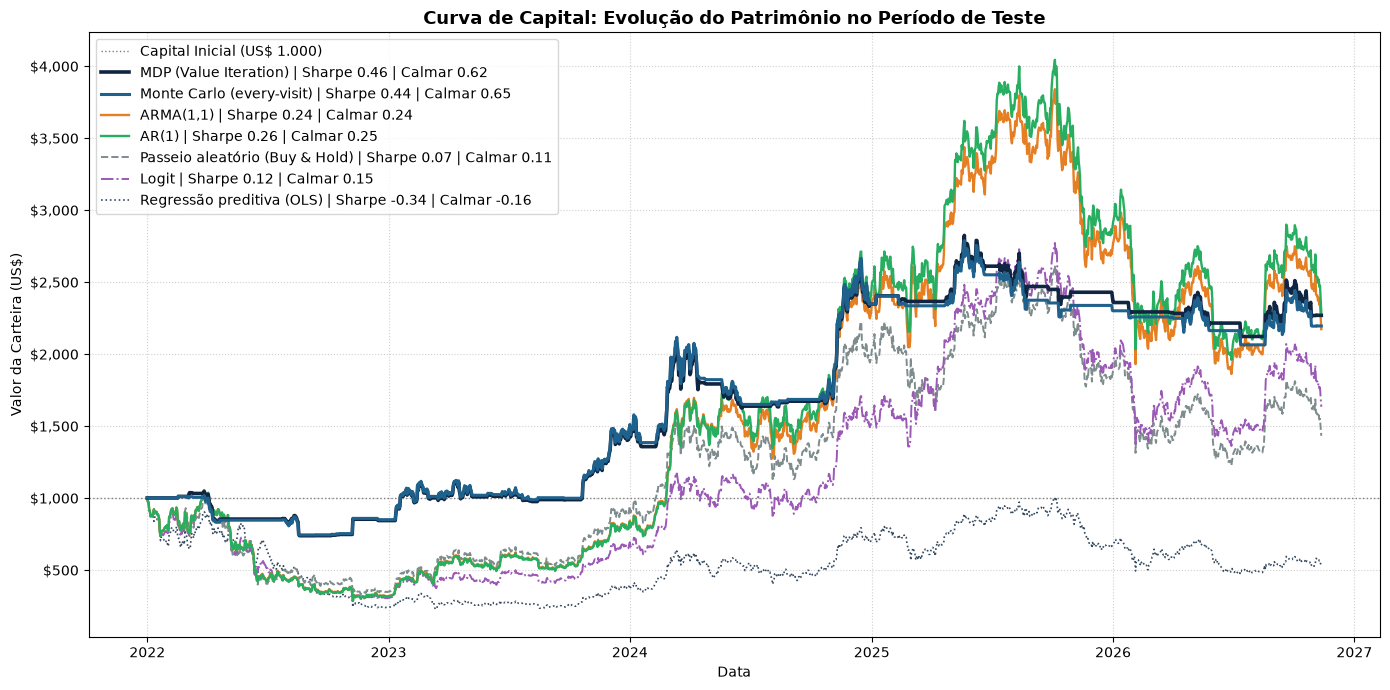

In [57]:
destaques = {
    "MDP (Value Iteration)":        dict(color="#102542", lw=2.6, zorder=5),
    NOME_MC:                        dict(color="#1F618D", lw=2.2, zorder=5),
    "ARMA(1,1)":                      dict(color="#E67E22", lw=1.7, zorder=4),
    "AR(1)":                          dict(color="#27AE60", lw=1.7, zorder=4),
    "Passeio aleatório (Buy & Hold)": dict(color="#7F8C8D", lw=1.4, ls="--", zorder=3),
    "Logit":                          dict(color="#9B59B6", lw=1.4, ls="-.", zorder=3),
    "Regressão preditiva (OLS)":      dict(color="#34495E", lw=1.2, ls=":", zorder=2),
}

fig, ax = plt.subplots(figsize=(14, 7))
ax.axhline(1000, color="gray", ls=":", lw=1, label="Capital Inicial (US$ 1.000)")
for nome, estilo in destaques.items():
    sharpe, calmar = df_ranking.loc[nome, ["Índice Sharpe", "Calmar"]]
    ax.plot(df_curvas.index, df_curvas[nome], label=f"{nome} | Sharpe {sharpe:.2f} | Calmar {calmar:.2f}", **estilo)

ax.set_title("Curva de Capital: Evolução do Patrimônio no Período de Teste", fontsize=13, fontweight="bold")
ax.set(xlabel="Data", ylabel="Valor da Carteira (US$)")
ax.yaxis.set_major_formatter("${x:,.0f}")
ax.grid(True, ls=":", alpha=0.6)
ax.legend(loc="upper left", fontsize=10)

plt.tight_layout()
plt.savefig("curva_patrimonio.png", dpi=300, bbox_inches="tight")
plt.show()

## 17. Resumo e conclusão
A tabela reúne as estratégias de RL e a referência Buy & Hold no **teste**, executadas no simulador.

In [58]:
principais = ["MDP (Value Iteration)", NOME_MC, "Buy & Hold"]
resumo = pd.DataFrame({n: resultados[("Teste", n)] for n in principais}).T
resumo["Concordância com VI"] = [f"{nS}/{nS}", f"{(pi_mc == pi_star).sum()}/{nS}", "—"]
display(resumo.style.format({
    "Patrimônio final": "US$ {:,.2f}", "Retorno total": "{:.2%}", "Retorno anual": "{:.2%}", "Sharpe": "{:.2f}",
    "Max drawdown": "{:.2%}", "Calmar": "{:.2f}", "Nº de trocas": "{:.0f}",
}))

,Patrimônio final,Retorno total,Retorno anual,Sharpe,Max drawdown,Calmar,Nº de trocas,Concordância com VI
MDP (Value Iteration),"US$ 2,278.03",127.80%,18.43%,0.46,-29.35%,0.63,113,27/27
Monte Carlo (every-visit),"US$ 2,194.69",119.47%,17.52%,0.44,-26.95%,0.65,108,22/27
Buy & Hold,"US$ 1,431.90",43.19%,7.65%,0.07,-66.93%,0.11,1,—


**Leitura dos resultados**

- **Value Iteration (model-based):** conhecendo o modelo estimado, encontra a política ótima de forma exata, em poucas iterações. É a referência.
- **Monte Carlo (model-free):** aprende só com experiência, sem estimar $\widehat P$ nem $\widehat R$. Por isso precisa de muitos episódios, e as estimativas de $Q$ têm ruído. Ações e estados pouco visitados são os mais afetados.
- **First-visit × every-visit:** o every-visit aproveita mais passagens por episódio (mais dados), enquanto o first-visit usa retornos mais independentes. A versão principal foi escolhida pelo Sharpe no treino, sem usar o teste.
- **Gulosa × ε-greedy:** sortear 10% das ações piora o resultado. Na média das sementes, o ε-greedy tem Sharpe menor, drawdown maior e mais que o dobro de trocas; ele só supera a política gulosa em uma minoria das sementes, por sorte. A exploração serve para **aprender** a política, não para operar com ela.
- **Variância entre sementes (5 rodadas do MC):** o every-visit é bem mais estável que o first-visit, com desvio padrão do Sharpe muito menor no treino e no teste, porque aproveita mais passagens por episódio. Já a **média** do Sharpe no treino favorece o first-visit: a semente 42 foi desfavorável a ele. Ou seja, com uma única rodada a escolha da versão depende da sorte. No teste, as médias das duas versões ficam próximas, dentro de um desvio padrão.
- **Estados raros:** transições bruscas de regime (baixa → alta e alta → baixa) quase não aparecem no treino. Nelas o MC tem pouca ou nenhuma informação, enquanto o VI usa o modelo estimado.
- **Custos de transação:** como o estado inclui a posição atual, as políticas de RL "sabem" que trocar custa caro e só mudam de posição quando compensa.
- **Benchmark econométrico:** os modelos lineares quase não conseguem prever o retorno diário (o R² da regressão preditiva fica perto de zero) e acabam parecidos com o Buy & Hold, carregando toda a queda do mercado. O ganho do MDP não vem de prever melhor o retorno, e sim de decidir **quando ficar exposto**. Isso aparece principalmente no **max drawdown** e no **Calmar**.

**Escolhas metodológicas:** todos os hiperparâmetros (κ, γ, H, ε, nº de episódios, semente) e o critério de escolha do MC foram fixados antes de olhar o teste, e as duas versões do MC usam exatamente os mesmos dados e parâmetros. O teste foi usado apenas para a avaliação final.

**Limitações:** estado simples (27 estados), um único ativo, uma única divisão treino/teste, apenas 5 sementes no Monte Carlo e custos simplificados (sem *slippage* nem aluguel no *short*). Não é recomendação de investimento.